In [1]:
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from sklearn.ensemble import RandomForestRegressor
from sklearn.decomposition import PCA
import joblib
import warnings

warnings.filterwarnings("ignore", category=RuntimeWarning)

In [2]:
PATH = r"E:\satdata\Custom\yucatan_sst_chlor_cdomslope_ssl_bathy_2010-2019_v4.pkl"
MODEL_PATH = r"F:\Programming\GitHub\nasa-murep\yucatan\experiments\isolation_forest\models\iforest_pipeline5.joblib"

features = ["sst_anom", "ssl_anom"]

In [3]:
with open(PATH, "rb") as f:
    blob = pickle.load(f)

df = blob["data"]
metadata = blob["metadata"]
df = df[(df.index.year >= 2010) & (df.index.year <= 2019)]

grid_shape = np.asarray(df["sst"].iloc[0]).shape

def shape_ok(a):
    return a is not None and np.asarray(a).shape == grid_shape 

keep = df["sst"].apply(shape_ok) & df["chlorophyll"].apply(shape_ok) & df["ssl"].apply(shape_ok)
df = df[keep]

sst_stack = np.stack(df["sst"].to_numpy()).astype(float)
chlor_stack = np.stack(df["chlorophyll"].to_numpy()).astype(float)
ssl_stack = np.stack(df["ssl"].to_numpy()).astype(float)

print(f"Loaded {len(df):,} days, grid shape {grid_shape}")

def same_day_anomaly(stack):
    daily_median = np.nanmedian(stack, axis=(1, 2), keepdims=True)
    return stack - daily_median

sst_anom_stack = same_day_anomaly(sst_stack)
ssl_anom_stack = same_day_anomaly(ssl_stack)

bathymetry = np.array(metadata["bathymetry"])

Loaded 3,651 days, grid shape (250, 250)


In [4]:
bundle = joblib.load(MODEL_PATH)
iforest_pipeline = bundle["iforest_pipeline"]
features = bundle.get("features", features)

preprocess = iforest_pipeline.named_steps["preprocess"]
iforest = iforest_pipeline.named_steps["iforest"]
print(f"Loaded pipeline from {MODEL_PATH}")
print(f"Features: {features}")

Loaded pipeline from F:\Programming\GitHub\nasa-murep\yucatan\experiments\isolation_forest\models\iforest_pipeline5.joblib
Features: ['sst_anom', 'ssl_anom']


In [45]:
DEPTH_CUTOFF = -20

In [46]:
def analyze_window(start_date, end_date, percentile):
    window_mask = (df.index >= start_date) & (df.index <= end_date)
    n_days = int(window_mask.sum())
    if n_days == 0:
        raise ValueError(f"No valid days found between {start_date.date()} and {end_date.date()}")

    with np.errstate(invalid="ignore"):
        mean_sst_anom = np.nanmean(sst_anom_stack[window_mask], axis=0)
        mean_ssl_anom = np.nanmean(ssl_anom_stack[window_mask], axis=0)
        mean_chlor = np.nanmean(chlor_stack[window_mask], axis=0)

    valid_2d = (
        ~np.isnan(mean_sst_anom) & ~np.isnan(mean_ssl_anom)
        & ~np.isnan(mean_chlor) & (mean_chlor > 0)
        & (bathymetry <= DEPTH_CUTOFF)  # only consider pixels at least 10m deep
    )
    row_w, col_w = np.where(valid_2d)

    X_window = pd.DataFrame({
        "sst_anom": mean_sst_anom[valid_2d],
        "ssl_anom": mean_ssl_anom[valid_2d],
    })[features]
    chlor_w = mean_chlor[valid_2d]  # descriptive only

    X_window_transformed = preprocess.transform(X_window)

    anomaly_score = -iforest.decision_function(X_window_transformed)
    raw_anomaly = anomaly_score >= np.percentile(anomaly_score, percentile)

    sst_anom_z = X_window_transformed["anom__sst_anom"].to_numpy()
    ssl_anom_z = X_window_transformed["anom__ssl_anom"].to_numpy()

    is_upwelling = (raw_anomaly
                    & (sst_anom_z < -0.5)
                    & (ssl_anom_z < 1)
                   )

    return {
        "start_date": start_date,
        "end_date": end_date,
        "n_days": n_days,
        "X_window": X_window,
        "chlor_w": chlor_w,
        "X_window_transformed": X_window_transformed,
        "anomaly_score": anomaly_score,
        "is_upwelling": is_upwelling,
        "non_upwelling": ~is_upwelling,
        "row_w": row_w,
        "col_w": col_w,
        "valid_2d": valid_2d,
    }

In [47]:
result = analyze_window(pd.Timestamp("2018-05-01"), pd.Timestamp("2018-05-28"), 80)

In [48]:
# predict IF anomaly score from transformed features
surrogate = RandomForestRegressor(n_estimators=100, max_depth=5, random_state=42, n_jobs=-1)
surrogate.fit(result["X_window_transformed"], result["anomaly_score"])

importances = surrogate.feature_importances_
feature_names = result["X_window_transformed"].columns
importance_dict = {name: weight * 100 for name, weight in zip(feature_names, importances)}

print("\n--- Feature Importance (% of variance in anomaly score explained) ---")
for feat, imp in sorted(importance_dict.items(), key=lambda item: item[1], reverse=True):
    print(f"{feat:>15}: {imp:>5.1f}%")


--- Feature Importance (% of variance in anomaly score explained) ---
 anom__ssl_anom:  86.6%
 anom__sst_anom:  13.4%


In [49]:
X_window = result["X_window"]
chlor_w = result["chlor_w"]
is_upwelling = result["is_upwelling"]
non_upwelling_mask = result["non_upwelling"]

print(f"\n--- Window: {result['start_date'].date()} to {result['end_date'].date()} ({result['n_days']} days averaged) ---")
print(f"Total Valid Pixels: {len(X_window):,}")
print(f"Upwelling Anomalies: {is_upwelling.sum():,}\n")

print("Mean States (Upwelling Anomaly vs Non-Anomaly):")
print(f"SST anom | Upwelling: {X_window['sst_anom'][is_upwelling].mean():.3f} \u00b0C | Non-Anomaly: {X_window['sst_anom'][non_upwelling_mask].mean():.3f} \u00b0C")
print(f"Chlor    | Upwelling: {chlor_w[is_upwelling].mean():.3f} mg/m3 | Non-Anomaly: {chlor_w[non_upwelling_mask].mean():.3f} mg/m3  (descriptive only, not a fit feature)")
print(f"SSL anom | Upwelling: {X_window['ssl_anom'][is_upwelling].mean():.3f} m | Non-Anomaly: {X_window['ssl_anom'][non_upwelling_mask].mean():.3f} m\n")


--- Window: 2018-05-01 to 2018-05-28 (28 days averaged) ---
Total Valid Pixels: 38,097
Upwelling Anomalies: 679

Mean States (Upwelling Anomaly vs Non-Anomaly):
SST anom | Upwelling: -1.608 °C | Non-Anomaly: 0.136 °C
Chlor    | Upwelling: 0.593 mg/m3 | Non-Anomaly: 0.146 mg/m3  (descriptive only, not a fit feature)
SSL anom | Upwelling: -0.059 m | Non-Anomaly: 0.098 m



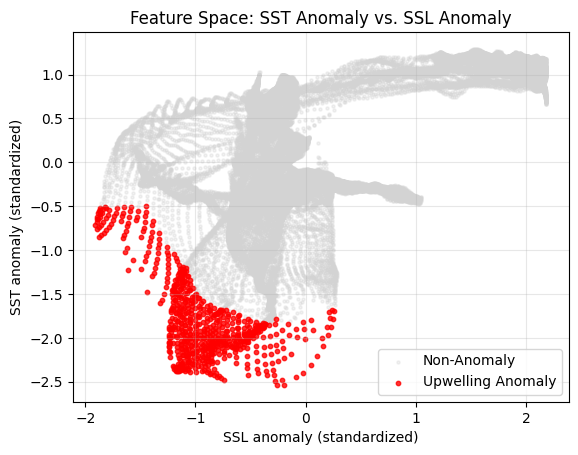

In [50]:
nu_ssl = result["X_window_transformed"]["anom__ssl_anom"][non_upwelling_mask]
u_ssl  = result["X_window_transformed"]["anom__ssl_anom"][is_upwelling]
nu_sst = result["X_window_transformed"]["anom__sst_anom"][non_upwelling_mask]
u_sst  = result["X_window_transformed"]["anom__sst_anom"][is_upwelling]

plt.scatter(nu_ssl, nu_sst,
            c='lightgray', alpha=0.3, s=5, label='Non-Anomaly')
plt.scatter(u_ssl, u_sst,
            c='red', alpha=0.8, s=10, label='Upwelling Anomaly')
plt.title("Feature Space: SST Anomaly vs. SSL Anomaly")
plt.xlabel("SSL anomaly (standardized)")
plt.ylabel("SST anomaly (standardized)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

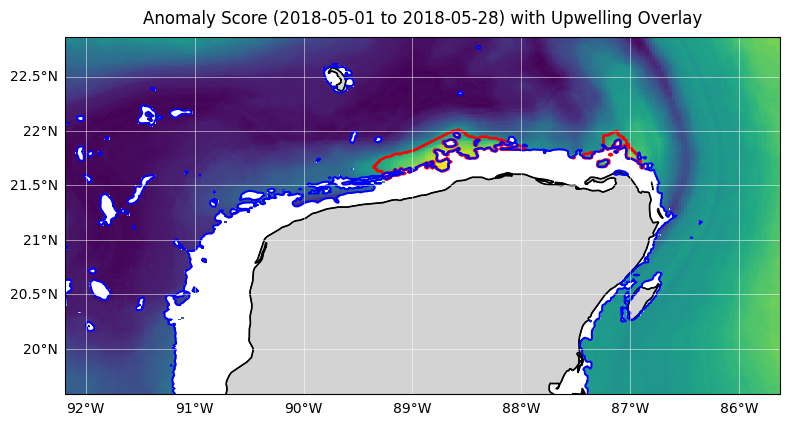

In [51]:
score_map = np.full(grid_shape, np.nan)
score_map[result["row_w"], result["col_w"]] = result["anomaly_score"]

binary_mask = np.zeros(grid_shape, dtype=float)
binary_mask[result["row_w"][is_upwelling], result["col_w"][is_upwelling]] = 1.0

lon_centers = np.array(metadata["lon_centers"])
lat_centers = np.array(metadata["lat_centers"])
lon_grid_2d, lat_grid_2d = np.meshgrid(lon_centers, lat_centers)

fig, ax = plt.subplots(figsize=(8, 6), subplot_kw={"projection": ccrs.PlateCarree()})

ax.set_extent(
    [lon_centers.min(), lon_centers.max(), lat_centers.min(), lat_centers.max()],
    crs=ccrs.PlateCarree(),
)

mesh = ax.pcolormesh(
    lon_grid_2d, lat_grid_2d, score_map,
    cmap="viridis", transform=ccrs.PlateCarree(), shading="auto"
)

ax.contour(
    lon_grid_2d, lat_grid_2d, binary_mask,
    levels=[0.5], colors="red", linewidths=2.0, transform=ccrs.PlateCarree()
)

ax.contour(
    lon_grid_2d, lat_grid_2d, bathymetry,
    levels=[DEPTH_CUTOFF], colors="blue", linewidths=1.5, linestyles="-", transform=ccrs.PlateCarree()
)

ax.add_feature(cfeature.LAND, facecolor="lightgray", edgecolor="black", linewidth=0.8)
ax.add_feature(cfeature.COASTLINE, linewidth=1.2)
gl = ax.gridlines(draw_labels=True, linewidth=0.6, color="white", alpha=0.6)
gl.top_labels = False
gl.right_labels = False

ax.set_title(f"Anomaly Score ({result['start_date'].date()} to {result['end_date'].date()}) with Upwelling Overlay", pad=10)
# fig.colorbar(mesh, ax=ax, orientation="vertical", shrink=0.8, pad=0.05)

plt.tight_layout()
plt.show()

In [11]:
december_result = analyze_window(pd.Timestamp("2018-12-01"), pd.Timestamp("2018-12-31"), 90)
print(f"December upwelling-flagged pixels: {december_result['is_upwelling'].sum():,} / {len(december_result['X_window']):,}")
print(f"July upwelling-flagged pixels:     {result['is_upwelling'].sum():,} / {len(result['X_window']):,}")

December upwelling-flagged pixels: 0 / 38,099
July upwelling-flagged pixels:     1 / 38,095
